# Nhận diện cảm xúc trong văn bản mạng xã hội tiếng Việt
## So sánh TF-IDF + SVM, CNN + Word2Vec, PhoBERT và ViSoBERT

Notebook chứa toàn bộ mã xử lý dữ liệu, huấn luyện, đánh giá và dự đoán. Xem **README.md** để cài môi trường, kiểm tra CPU/GPU và chọn kernel VS Code.

**Bài toán:** mỗi câu nhận một trong bảy nhãn cảm xúc UIT-VSMEC. **Mục tiêu:** so sánh bốn phương pháp trên cùng split, giải thích lỗi và xây dựng demo. Không nghiên cứu lập trường và không gộp nhãn thành positive/negative.

Chạy tuần tự lần đầu. Sau khi có checkpoint, giữ `RETRAIN = False` để xem lại kết quả mà không huấn luyện lại. Đổi thành `True` khi muốn chạy lại; checkpoint của lần chạy trước trong thư mục này sẽ được cập nhật. Có thể chọn riêng tên mô hình trong `MODELS_TO_RUN`.

## 1. Đọc dữ liệu và cấu hình thí nghiệm
Ba tập chính thức được giữ nguyên. Vocabulary và IDF chỉ học từ train; validation dùng chọn checkpoint. Test dùng đánh giá sau khi chốt mô hình.

In [1]:
from pathlib import Path
import os, json, random, re, unicodedata, time, gc, hashlib, platform
from datetime import datetime, timezone
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from gensim.models import Word2Vec
from pyvi import ViTokenizer
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from IPython.display import display, Image

PROJECT_ROOT = Path(globals().get('PROJECT_ROOT', Path.cwd())).resolve()
if not (PROJECT_ROOT/'data'/'raw').exists():
    raise FileNotFoundError('Mở VS Code tại thư mục gốc đồ án có data/raw. Xem README.md.')
LABELS = ['Anger','Disgust','Enjoyment','Fear','Other','Sadness','Surprise']
LABEL_VI = dict(zip(LABELS,['Tức giận','Ghê tởm','Vui thích','Sợ hãi','Khác','Buồn','Ngạc nhiên']))
NAMES = {'svm':'TF-IDF + SVM','cnn_word2vec':'CNN + Word2Vec','phobert':'PhoBERT','visobert':'ViSoBERT'}
CONFIG = {
 'seed':42, 'labels':LABELS,
 'svm':{'C':1.0,'class_weight':'balanced','word_ngram':[1,3],'char_ngram':[3,5]},
 'cnn':{'embedding_dim':300,'filters':128,'kernel_sizes':[3,4,5],'dropout':0.5,'batch_size':64,'epochs':20,'patience':4,'learning_rate':0.001,'max_length':64,'word2vec_epochs':20},
 'transformer':{'max_length':128,'batch_size':4,'gradient_accumulation_steps':4,'epochs':4,'patience':2,'learning_rate':2e-5,'weight_decay':0.01},
 'pretrained':{'phobert':'vinai/phobert-base-v2','visobert':'uitnlp/visobert'},
 'preprocessing':{'version':'nfc_pyvi_v1','phobert':'Pyvi word segmentation','visobert':'normalized original text','cnn':'Pyvi lowercase','svm':'Pyvi word + original character'}
}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
def save_json(value,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,ensure_ascii=False,indent=2),encoding='utf-8')
def normalized(text):
    text=unicodedata.normalize('NFC',str(text))
    text=re.sub(r'https?://\S+|www\.\S+',' URL ',text)
    text=re.sub(r'@[\w.]+',' USER ',text)
    return re.sub(r'\s+',' ',text).strip()
def segmented(text): return ViTokenizer.tokenize(normalized(text))
def free_memory():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

d:\2. PERSONALIZATION\8. PYTHON-REINSTALL\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RETRAIN = False
MODELS_TO_RUN = ['svm','cnn_word2vec','phobert','visobert']
for folder in ['models','results','data/processed']:
    (PROJECT_ROOT/folder).mkdir(parents=True,exist_ok=True)
save_json(CONFIG, PROJECT_ROOT/'results/config.json')
RAW_FILES={'train':'train_nor_811.xlsx','validation':'valid_nor_811.xlsx','test':'test_nor_811.xlsx'}
frames={}
for split,filename in RAW_FILES.items():
    frame=pd.read_excel(PROJECT_ROOT/'data/raw'/filename).rename(columns={'Emotion':'label','Sentence':'text','Unnamed: 0':'source_id'})
    assert frame['text'].notna().all() and frame['label'].isin(LABELS).all()
    frame=frame[['source_id','text','label']].copy()
    frame['label_id']=frame.label.map({x:i for i,x in enumerate(LABELS)})
    frame['normalized']=frame.text.map(normalized)
    assert frame.normalized.str.len().gt(0).all()
    frames[split]=frame
assert {s:len(f) for s,f in frames.items()}=={'train':5548,'validation':686,'test':693}
display(pd.DataFrame({'split':list(frames),'số câu':[len(f) for f in frames.values()]}))
display(frames['train'].groupby('label').head(1)[['text','label']])

,split,số câu
0,train,5548
1,validation,686
2,test,693


,text,label
0,cho mình xin bài nhạc tên là gì với ạ,Other
1,cho đáng đời con quỷ . về nhà lôi con nhà mày ...,Disgust
3,uớc gì sau này về già vẫn có thể như cụ này :)),Enjoyment
5,thằng kia sao mày bắt vợ với bồ tao dọn thế ki...,Anger
7,thật hay đùa ác vậy . không thể tin được,Surprise
9,per nghe đi rồi khóc 1 trận cho thoải mái . đừ...,Sadness
18,thời buổi bây chừ chuyện gì cũng có thể xảy ra...,Fear


## 2. Phân tích dữ liệu
`Other` là nhãn khác theo định nghĩa bộ dữ liệu, không đồng nghĩa tuyệt đối với trung tính. Phân bố nhãn lệch làm Accuracy chưa phản ánh đủ hiệu quả ở nhãn hiếm. Do đó dùng **Macro-F1** làm chỉ số chính.

Kiểm tra trùng lặp để ghi nhận chất lượng dữ liệu; không âm thầm thay split chuẩn. Nếu có trùng lặp giữa các tập, kết quả cần được diễn giải với giới hạn đó.

,train,validation,test
label,,,
Anger,391,49,40
Disgust,1071,135,132
Enjoyment,1558,214,193
Fear,318,31,46
Other,1021,141,129
Sadness,947,86,116
Surprise,242,30,37


{'within': {'train': 4, 'validation': 0, 'test': 1},
 'across': {'train_validation': 1, 'train_test': 0, 'validation_test': 0}}

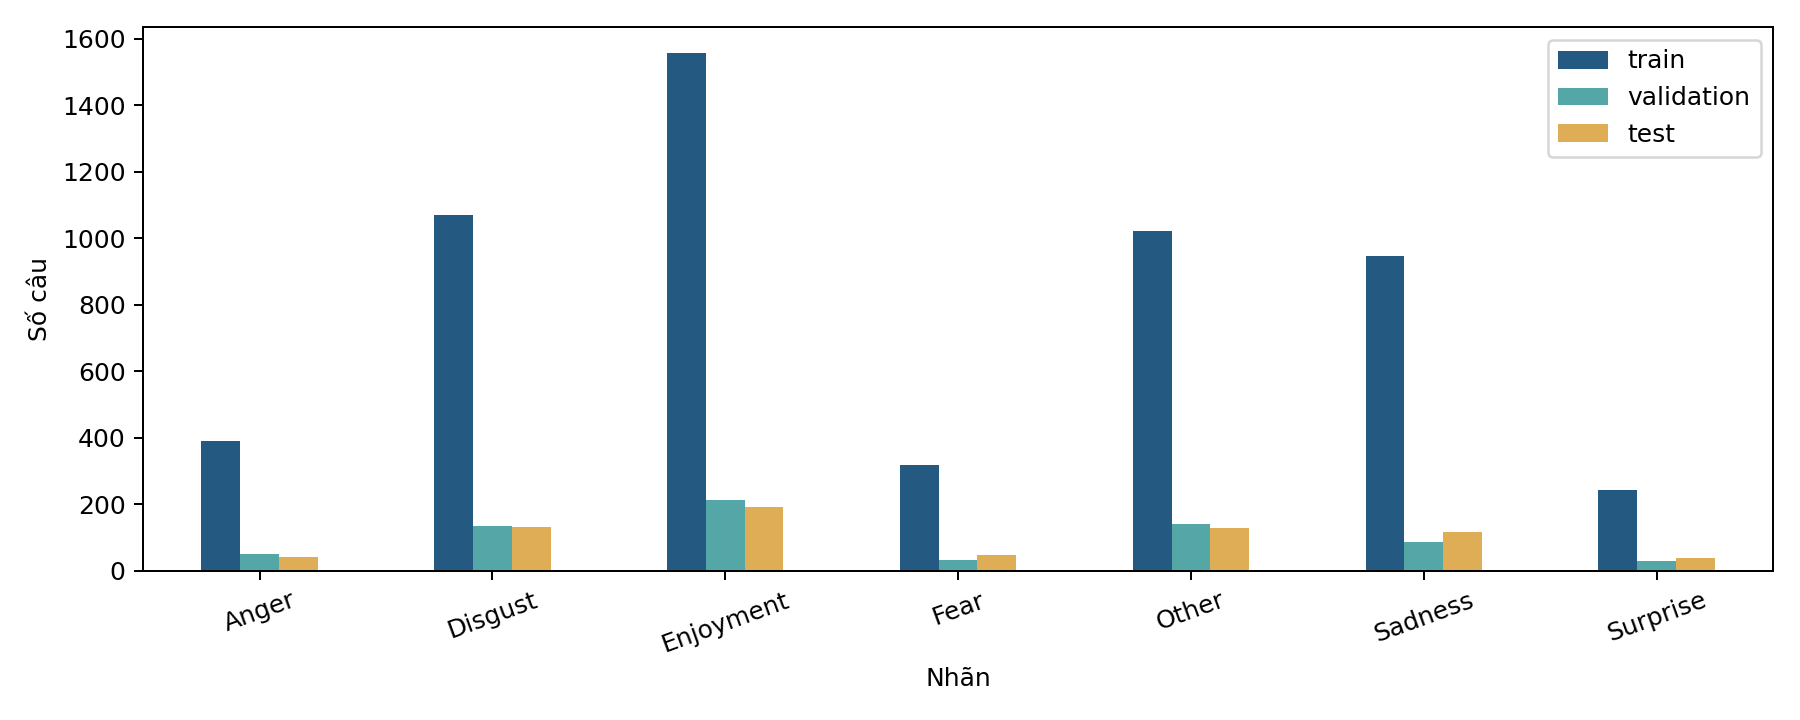

In [4]:
counts=pd.DataFrame({s:f.label.value_counts().reindex(LABELS,fill_value=0) for s,f in frames.items()})
display(counts)
audit={'within':{s:int(f.normalized.duplicated().sum()) for s,f in frames.items()},'across':{}}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    audit['across'][a+'_'+b]=int(frames[b].normalized.isin(set(frames[a].normalized)).sum())
save_json(audit,PROJECT_ROOT/'results/data_audit.json')
display(audit)
counts.to_csv(PROJECT_ROOT/'results/label_distribution.csv',encoding='utf-8-sig')
ax=counts.plot.bar(figsize=(10,4),color=['#245A81','#55A6A6','#DFAD55'])
ax.set_ylabel('Số câu'); ax.set_xlabel('Nhãn'); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig(PROJECT_ROOT/'results/label_distribution.png',dpi=180); plt.close()
display(Image(filename=str(PROJECT_ROOT/'results/label_distribution.png')))
stats={s:{'samples':len(f),'label_counts':f.label.value_counts().to_dict(),'median_syllables':float(f.normalized.str.split().str.len().median())} for s,f in frames.items()}
save_json(stats,PROJECT_ROOT/'results/data_statistics.json')

## 3. Tiền xử lý tiếng Việt
Chuẩn hóa Unicode NFC, khoảng trắng, URL và mention; giữ dấu tiếng Việt, emoji và từ phủ định. Dùng Pyvi cho word n-gram của SVM, Word2Vec/CNN và PhoBERT. ViSoBERT dùng văn bản chuẩn hóa chưa nối từ bằng dấu gạch dưới.

Các mô hình có cùng câu đầu vào và split, nhưng tokenizer phù hợp với từng kiến trúc. Không mặc định một cách tiền xử lý phù hợp cho tất cả. Trong thí nghiệm này không xóa hàng loạt stopwords vì có thể làm mất “không”, “chưa”.

In [5]:
for split,frame in frames.items():
    frame['segmented']=frame.normalized.map(segmented)
    frame.to_csv(PROJECT_ROOT/'data/processed'/f'{split}.csv',index=False,encoding='utf-8-sig')
display(frames['train'][['text','normalized','segmented']].head(5))
manifest={'created_utc':datetime.now(timezone.utc).isoformat(),'python':platform.python_version(),'device':str(DEVICE),'gpu':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,'seed':CONFIG['seed'],'raw_sha256':{name:hashlib.sha256((PROJECT_ROOT/'data/raw'/name).read_bytes()).hexdigest() for name in RAW_FILES.values()},'packages':{p:importlib.metadata.version(p) for p in ['torch','transformers','gensim','pyvi','scikit-learn','numpy','pandas']}}
save_json(manifest,PROJECT_ROOT/'results/run_manifest.json')

,text,normalized,segmented
0,cho mình xin bài nhạc tên là gì với ạ,cho mình xin bài nhạc tên là gì với ạ,cho mình xin bài nhạc tên là gì với ạ
1,cho đáng đời con quỷ . về nhà lôi con nhà mày ...,cho đáng đời con quỷ . về nhà lôi con nhà mày ...,cho đáng_đời con quỷ . về nhà lôi con nhà mày ...
2,lo học đi . yêu đương lol gì hay lại thích học...,lo học đi . yêu đương lol gì hay lại thích học...,lo học đi . yêu_đương lol gì hay lại thích học...
3,uớc gì sau này về già vẫn có thể như cụ này :)),uớc gì sau này về già vẫn có thể như cụ này :)),uớc gì sau_này về già vẫn có_thể như cụ này : ) )
4,mỗi lần có video của con là cứ coi đi coi lại ...,mỗi lần có video của con là cứ coi đi coi lại ...,mỗi lần có video của con là cứ coi đi coi lại ...


## 4. Hàm đánh giá dùng chung
Mỗi mô hình dự đoán một nhãn. Macro-F1 là trung bình F1 của bảy lớp với trọng số bằng nhau; Weighted-F1 có trọng số theo số mẫu. Hàm dưới lưu cả dự đoán từng câu để kiểm tra lại metric và phân tích lỗi.

Checkpoint CNN/Transformer được chọn bằng Macro-F1 validation, không chọn bằng test. Thời gian huấn luyện tính riêng, chưa bao gồm tải mô hình nền.

In [7]:
def evaluate(key,pred,train_seconds,best_validation=None):
    test=frames['test']; gold=test.label_id.to_numpy()
    metrics={'model':NAMES[key],'key':key,'accuracy':float(accuracy_score(gold,pred)),
       'macro_f1':float(f1_score(gold,pred,labels=range(7),average='macro',zero_division=0)),
       'weighted_f1':float(f1_score(gold,pred,labels=range(7),average='weighted',zero_division=0)),
       'train_seconds':train_seconds,'best_validation_macro_f1':best_validation,
       'report':classification_report(gold,pred,labels=range(7),target_names=LABELS,output_dict=True,zero_division=0)}
    dest=PROJECT_ROOT/'results'/key; dest.mkdir(parents=True,exist_ok=True)
    save_json(metrics,dest/'metrics.json')
    rows=test[['source_id','text','label','label_id']].copy(); rows['prediction_id']=pred
    rows['prediction']=[LABELS[int(i)] for i in pred]; rows['correct']=rows.label_id.eq(rows.prediction_id)
    rows.to_csv(dest/'predictions.csv',index=False,encoding='utf-8-sig')
    matrix=confusion_matrix(gold,pred,labels=range(7))
    pd.DataFrame(matrix,index=LABELS,columns=LABELS).to_csv(dest/'confusion_matrix.csv')
    fig,ax=plt.subplots(figsize=(8,6)); sns.heatmap(matrix,annot=True,fmt='d',cmap='Blues',xticklabels=LABELS,yticklabels=LABELS,ax=ax)
    ax.set(xlabel='Dự đoán',ylabel='Nhãn thật',title=NAMES[key]); fig.tight_layout(); fig.savefig(dest/'confusion_matrix.png',dpi=180); plt.close(fig)
    display(pd.DataFrame([metrics])[['model','accuracy','macro_f1','weighted_f1','train_seconds']])
    return metrics
def completed(key): return (PROJECT_ROOT/'results'/key/'metrics.json').exists() and (PROJECT_ROOT/'models'/key).exists()
def previous(key): display(pd.read_json(PROJECT_ROOT/'results'/key/'metrics.json',typ='series')[['model','accuracy','macro_f1','weighted_f1']])

## 5. TF-IDF và Linear SVM
TF-IDF biến văn bản thành vector thưa, giảm trọng số từ xuất hiện trong nhiều câu. Dùng word n-gram 1–3 và character n-gram 3–5 để bổ sung thông tin cách viết, teencode. Linear SVM học ranh giới phân lớp trên vector này; `class_weight='balanced'` điều chỉnh phạt theo tần suất lớp.

In [8]:
def train_svm():
    set_seed(); start=time.perf_counter()
    word=TfidfVectorizer(ngram_range=(1,3),min_df=2,max_features=80000,sublinear_tf=True)
    char=TfidfVectorizer(analyzer='char',ngram_range=(3,5),min_df=2,max_features=120000,sublinear_tf=True)
    tr=frames['train']; va=frames['validation']; te=frames['test']
    x=hstack([word.fit_transform(tr.segmented),char.fit_transform(tr.normalized)]).tocsr()
    model=LinearSVC(C=1.,class_weight='balanced',random_state=42)
    model.fit(x,tr.label_id); seconds=time.perf_counter()-start
    def features(f): return hstack([word.transform(f.segmented),char.transform(f.normalized)]).tocsr()
    val=f1_score(va.label_id,model.predict(features(va)),average='macro')
    dest=PROJECT_ROOT/'models/svm'; dest.mkdir(parents=True,exist_ok=True)
    joblib.dump({'model':model,'word':word,'char':char,'labels':LABELS},dest/'model.joblib')
    evaluate('svm',model.predict(features(te)),seconds,float(val))
if 'svm' in MODELS_TO_RUN:
    if RETRAIN or not completed('svm'): train_svm()
    else: previous('svm')

model          TF-IDF + SVM
accuracy           0.575758
macro_f1           0.560349
weighted_f1        0.575338
dtype: object

## 6. Word2Vec và TextCNN
Word2Vec Skip-gram (`sg=1`) học vector từ bằng dự đoán ngữ cảnh. Chỉ dùng câu train để học embedding 300 chiều. TextCNN trượt các bộ lọc có độ rộng 3, 4, 5 từ, dùng ReLU và global max pooling, ghép đặc trưng rồi phân loại bảy lớp.

Embedding tiếp tục được cập nhật khi học CNN. Padding được loại khỏi phép lấy max của các cửa sổ hoàn toàn chứa padding. `<UNK>` xử lý từ ngoài vocabulary. Mô hình nhỏ và dễ chạy nhưng embedding từ corpus nhỏ có thể chưa tốt.

In [9]:
class TextCNN(nn.Module):
    def __init__(self,embeddings,params):
        super().__init__(); weights=torch.as_tensor(embeddings,dtype=torch.float32)
        self.embedding=nn.Embedding.from_pretrained(weights,freeze=False,padding_idx=0)
        self.convs=nn.ModuleList([nn.Conv1d(weights.shape[1],params['filters'],k) for k in params['kernel_sizes']])
        self.dropout=nn.Dropout(params['dropout']); self.classifier=nn.Linear(params['filters']*len(params['kernel_sizes']),len(LABELS))
    def forward(self,ids):
        values=self.embedding(ids).transpose(1,2); mask=(ids!=0).float().unsqueeze(1)
        pooled=[]
        for conv in self.convs:
            active=torch.nn.functional.max_pool1d(mask,conv.kernel_size[0],stride=1)>0
            scores=torch.relu(conv(values)).masked_fill(~active,torch.finfo(values.dtype).min)
            pooled.append(scores.amax(2))
        return self.classifier(self.dropout(torch.cat(pooled,dim=1)))
def cnn_ids(texts,vocab,max_length):
    rows=[]
    for text in texts:
        ids=[vocab.get(t,1) for t in text.lower().split()][:max_length] or [1]
        rows.append(ids+[0]*(max_length-len(ids)))
    return torch.tensor(rows,dtype=torch.long)

In [11]:
@torch.no_grad()
def cnn_predict(model,loader):
    model.eval(); gold=[]; pred=[]
    for ids,labels in loader:
        pred.extend(model(ids.to(DEVICE)).argmax(1).cpu().tolist()); gold.extend(labels.tolist())
    return gold,pred
def train_cnn():
    set_seed(); p=CONFIG['cnn']; start=time.perf_counter()
    tokens=[t.lower().split() for t in frames['train'].segmented]
    w2v=Word2Vec(tokens,vector_size=p['embedding_dim'],window=5,min_count=1,workers=1,sg=1,epochs=p['word2vec_epochs'],seed=42)
    vocab={w:i+2 for i,w in enumerate(w2v.wv.index_to_key)}
    emb=np.zeros((len(vocab)+2,p['embedding_dim']),dtype=np.float32); emb[1]=np.random.normal(0,.05,p['embedding_dim'])
    for w,i in vocab.items(): emb[i]=w2v.wv[w]
    def loader(split,shuffle=False):
        f=frames[split]; ds=torch.utils.data.TensorDataset(cnn_ids(f.segmented,vocab,p['max_length']),torch.tensor(f.label_id.tolist()))
        return DataLoader(ds,batch_size=p['batch_size'],shuffle=shuffle,num_workers=0)
    trainloader=loader('train',True); validloader=loader('validation'); testloader=loader('test')
    model=TextCNN(emb,p).to(DEVICE); opt=torch.optim.Adam(model.parameters(),lr=p['learning_rate'],weight_decay=1e-4)
    criterion=nn.CrossEntropyLoss(); best=-1.; best_state=None; stale=0; history=[]
    for epoch in range(1,p['epochs']+1):
        model.train(); losses=0.
        for ids,y in trainloader:
            opt.zero_grad(); loss=criterion(model(ids.to(DEVICE)),y.to(DEVICE)); loss.backward(); opt.step(); losses+=loss.item()*len(y)
        gold,pred=cnn_predict(model,validloader); score=float(f1_score(gold,pred,average='macro',zero_division=0))
        history.append({'epoch':epoch,'train_loss':losses/len(frames['train']),'validation_macro_f1':score}); print(history[-1],flush=True)
        if score>best:
            best=score; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; stale=0
        else:
            stale+=1
            if stale>=p['patience']: break
    seconds=time.perf_counter()-start; model.load_state_dict(best_state)
    dest=PROJECT_ROOT/'models/cnn_word2vec'; dest.mkdir(parents=True,exist_ok=True)
    torch.save({'state_dict':best_state,'embeddings':emb,'vocab':vocab,'params':p,'labels':LABELS},dest/'model.pt')
    w2v.save(str(dest/'word2vec.model'))
    evaluate('cnn_word2vec',cnn_predict(model,testloader)[1],seconds,best)
    save_json(history,PROJECT_ROOT/'results/cnn_word2vec/history.json')
    del model,opt,w2v,best_state; free_memory()
if 'cnn_word2vec' in MODELS_TO_RUN:
    if RETRAIN or not completed('cnn_word2vec'): train_cnn()
    else: previous('cnn_word2vec')

model          CNN + Word2Vec
accuracy             0.598846
macro_f1             0.553276
weighted_f1          0.596956
dtype: object

## 7. Hàm fine-tune Transformer dùng chung
PhoBERT và ViSoBERT tạo biểu diễn theo ngữ cảnh bằng self-attention. Fine-tuning cập nhật mô hình nền và lớp phân loại bằng nhãn cảm xúc; không tiền huấn luyện từ đầu.

Hai mô hình dùng tối đa 4 epoch, learning rate 2e-5, batch 4 và tích lũy gradient 4 bước (effective batch khoảng 16). Chọn checkpoint bằng Macro-F1 validation và early stopping. Mixed precision giảm bộ nhớ GPU. Batch tích lũy cuối epoch được chuẩn hóa theo số mẫu thực tế.

Cùng siêu tham số giúp thiết lập dễ đối chiếu nhưng không bảo đảm mỗi mô hình đạt cấu hình tối ưu riêng.

In [12]:
class TransformerDataset(Dataset):
    def __init__(self,frame,tokenizer,key,max_length):
        text=frame.segmented if key=='phobert' else frame.normalized
        self.enc=tokenizer(text.tolist(),padding='max_length',truncation=True,max_length=max_length,return_tensors='pt')
        self.y=torch.tensor(frame.label_id.tolist())
    def __len__(self): return len(self.y)
    def __getitem__(self,i): return {**{k:v[i] for k,v in self.enc.items()},'labels':self.y[i]}
@torch.no_grad()
def transformer_predict(model,loader):
    model.eval(); gold=[]; pred=[]
    for batch in loader:
        gold.extend(batch['labels'].tolist()); x={k:v.to(DEVICE) for k,v in batch.items() if k!='labels'}
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=DEVICE.type=='cuda'):
            logits=model(**x).logits
        pred.extend(logits.argmax(1).cpu().tolist())
    return gold,pred
def train_transformer(key):
    set_seed(); free_memory(); p=CONFIG['transformer']; name=CONFIG['pretrained'][key]
    tokenizer=AutoTokenizer.from_pretrained(name,use_fast=False)
    model=AutoModelForSequenceClassification.from_pretrained(name,num_labels=7,id2label=dict(enumerate(LABELS)),label2id={v:i for i,v in enumerate(LABELS)})
    model.to(DEVICE)
    loaders={s:DataLoader(TransformerDataset(f,tokenizer,key,p['max_length']),batch_size=p['batch_size'] if s=='train' else 8,shuffle=s=='train',num_workers=0) for s,f in frames.items()}
    opt=torch.optim.AdamW(model.parameters(),lr=p['learning_rate'],weight_decay=p['weight_decay'])
    accum=p['gradient_accumulation_steps']; batches=len(loaders['train']); updates=(batches+accum-1)//accum
    scheduler=get_linear_schedule_with_warmup(opt,num_warmup_steps=int(updates*p['epochs']*.1),num_training_steps=updates*p['epochs'])
    scaler=torch.amp.GradScaler('cuda',enabled=DEVICE.type=='cuda')
    best=-1.; best_state=None; stale=0; history=[]; start=time.perf_counter()
    for epoch in range(1,p['epochs']+1):
        model.train(); opt.zero_grad(); total=0.
        for step,batch in enumerate(loaders['train']):
            x={k:v.to(DEVICE) for k,v in batch.items()}; size=len(x['labels'])
            group_start=(step//accum)*accum*p['batch_size']
            group_samples=min(accum*p['batch_size'],len(frames['train'])-group_start)
            with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=DEVICE.type=='cuda'):
                raw_loss=model(**x).loss; loss=raw_loss*size/group_samples
            scaler.scale(loss).backward(); total+=raw_loss.item()*size
            if (step+1)%accum==0 or step+1==batches:
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(),1.)
                old_scale=scaler.get_scale(); scaler.step(opt); scaler.update()
                if scaler.get_scale()>=old_scale: scheduler.step()
                opt.zero_grad()
        gold,pred=transformer_predict(model,loaders['validation']); score=float(f1_score(gold,pred,average='macro',zero_division=0))
        history.append({'epoch':epoch,'train_loss':total/len(frames['train']),'validation_macro_f1':score}); print(key,history[-1],flush=True)
        save_json(history,PROJECT_ROOT/'results'/key/'history.json')
        if score>best:
            best=score; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; stale=0
        else:
            stale+=1
            if stale>=p['patience']: break
    seconds=time.perf_counter()-start; model.load_state_dict(best_state)
    dest=PROJECT_ROOT/'models'/key; model.save_pretrained(dest); tokenizer.save_pretrained(dest)
    evaluate(key,transformer_predict(model,loaders['test'])[1],seconds,best)
    del model,opt,scaler,scheduler,best_state,loaders; free_memory()

## 8. PhoBERT
Dùng checkpoint `vinai/phobert-base-v2`, một mô hình tiếng Việt dựa trên RoBERTa. Đầu vào được tách từ bằng Pyvi trước subword tokenizer. Phải phân biệt checkpoint base-v2 với các phiên bản PhoBERT khác khi mô tả mô hình.

In [13]:
if 'phobert' in MODELS_TO_RUN:
    if RETRAIN or not completed('phobert'): train_transformer('phobert')
    else: previous('phobert')

model           PhoBERT
accuracy       0.666667
macro_f1       0.605097
weighted_f1    0.660494
dtype: object

## 9. ViSoBERT
Dùng checkpoint `uitnlp/visobert` được tiền huấn luyện cho văn bản mạng xã hội tiếng Việt. Giữ emoji và đầu vào chuẩn hóa không nối từ. Giả thuyết phù hợp miền không đồng nghĩa chắc chắn đạt điểm cao hơn; kết luận dựa vào thực nghiệm của nhóm.

In [14]:
if 'visobert' in MODELS_TO_RUN:
    if RETRAIN or not completed('visobert'): train_transformer('visobert')
    else: previous('visobert')

model          ViSoBERT
accuracy       0.627706
macro_f1        0.59553
weighted_f1    0.625292
dtype: object

## 10. Kết quả thực nghiệm của nhóm
So sánh bốn mô hình cùng split và bộ nhãn. Chọn mô hình demo mặc định bằng điểm validation. 

,key,model,accuracy,macro_f1,weighted_f1,train_seconds,best_validation_macro_f1
2,phobert,PhoBERT,0.666667,0.605097,0.660494,548.433027,0.541993
3,visobert,ViSoBERT,0.627706,0.595530,0.625292,479.728969,0.534227
0,svm,TF-IDF + SVM,0.575758,0.560349,0.575338,2.175393,0.524126
1,cnn_word2vec,CNN + Word2Vec,0.598846,0.553276,0.596956,25.507723,0.507357


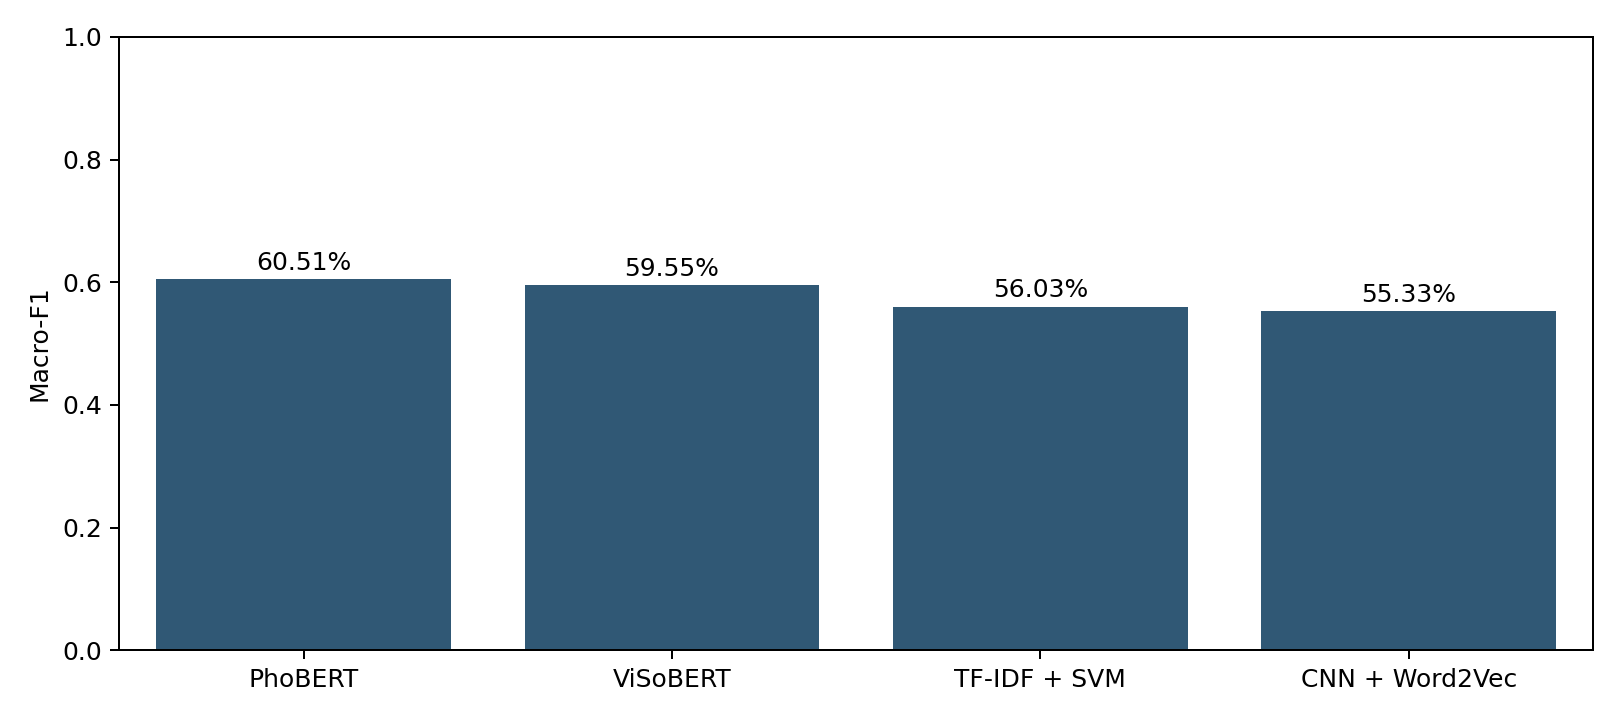

In [22]:
metrics=[]
for key in NAMES:
    path=PROJECT_ROOT/'results'/key/'metrics.json'
    if path.exists(): metrics.append(json.loads(path.read_text(encoding='utf-8')))
comparison=pd.DataFrame([{k:m[k] for k in ['key','model','accuracy','macro_f1','weighted_f1','train_seconds','best_validation_macro_f1']} for m in metrics]).sort_values('macro_f1',ascending=False)
comparison.to_csv(PROJECT_ROOT/'results/model_comparison.csv',index=False,encoding='utf-8-sig')
save_json(comparison.to_dict('records'),PROJECT_ROOT/'results/model_comparison.json')
display(comparison)
majority=int(frames['train'].label_id.mode()[0]); constant=np.full(len(frames['test']),majority)
baseline={'label':LABELS[majority],'accuracy':float(accuracy_score(frames['test'].label_id,constant)),'macro_f1':float(f1_score(frames['test'].label_id,constant,average='macro',zero_division=0))}
save_json(baseline, PROJECT_ROOT/'results/majority_baseline.json')
chosen=max(metrics,key=lambda m:m['best_validation_macro_f1'])['key'] ## Chọn mô hình tốt nhất dựa trên macro-F1 trên tập validation
save_json({'default_model':chosen,'selection':'validation_macro_f1'},PROJECT_ROOT/'models/demo_config.json')
fig,ax=plt.subplots(figsize=(9,4)); sns.barplot(data=comparison,x='model',y='macro_f1',color='#245A81',ax=ax)
ax.set_ylim(0,1); ax.set_ylabel('Macro-F1'); ax.set_xlabel('')
for i,v in enumerate(comparison.macro_f1): ax.text(i,v+.015,f'{v:.2%}',ha='center')
fig.tight_layout(); fig.savefig(PROJECT_ROOT/'results/model_comparison.png',dpi=180); plt.close(fig)
display(Image(filename=str(PROJECT_ROOT/'results/model_comparison.png')))
for key in ['cnn_word2vec','phobert','visobert']:
    path=PROJECT_ROOT/'results'/key/'history.json'
    if path.exists():
        h=pd.read_json(path); fig,ax=plt.subplots(figsize=(7,3)); ax.plot(h.epoch,h.validation_macro_f1,marker='o'); ax.set(xlabel='Epoch',ylabel='Validation Macro-F1',title=NAMES[key]); fig.tight_layout(); fig.savefig(path.parent/'learning_curve.png',dpi=160); plt.close(fig)

## 11. Phân tích lỗi và giới hạn
Xem F1 từng nhãn, các cặp nhầm nhiều và đọc lại câu. Bảng dưới chỉ xác định lỗi quan sát được; giải thích mỉa mai, thiếu ngữ cảnh hoặc nhãn nhập nhằng cần người đọc kiểm tra, không coi nhãn gốc sai chỉ vì mô hình dự đoán khác.

Giới hạn: corpus nhỏ và lệch nhãn, một seed, ngân sách 4 epoch cho Transformer, Word2Vec chỉ học từ train, Pyvi có thể tách sai slang. Hướng cải thiện là kiểm tra lỗi tiền xử lý và chạy nhiều seed/tuning trên validation.

,text,label,prediction
0,người ta có bạn bè nhìn vui thật,Sadness,Enjoyment
1,cho nghỉ viêc mói đúng sao goi là kỷ luật,Surprise,Disgust
4,bố không thích nộp đấy mày thích ý kiến không,Anger,Other
5,bắt cóc bỏ đĩa . quanh đi quẩn lại chỉ khổ dân...,Other,Disgust
9,per trình mày vẫn còn thấp chán =)),Other,Disgust
15,ổng quay thiệt mà sao chửi ổng thế . không qua...,Other,Disgust
19,mệt vãi .. mà cừời cũng vãi ??????,Enjoyment,Sadness
21,hậu duệ mặt trời đấy chứ đùa đâu nhá 😗😗,Other,Enjoyment
24,trơi ơi sao lại cháy chứ,Surprise,Other
25,có những người không có ý thức bỏ quần áo rách...,Disgust,Other


số lỗi
label     prediction        
Enjoyment Other           19
Anger     Disgust         16
Other     Enjoyment       15
          Sadness         15
          Disgust         14
Enjoyment Sadness         14
          Disgust         11
Disgust   Other           11
Surprise  Other           10
Sadness   Enjoyment        9

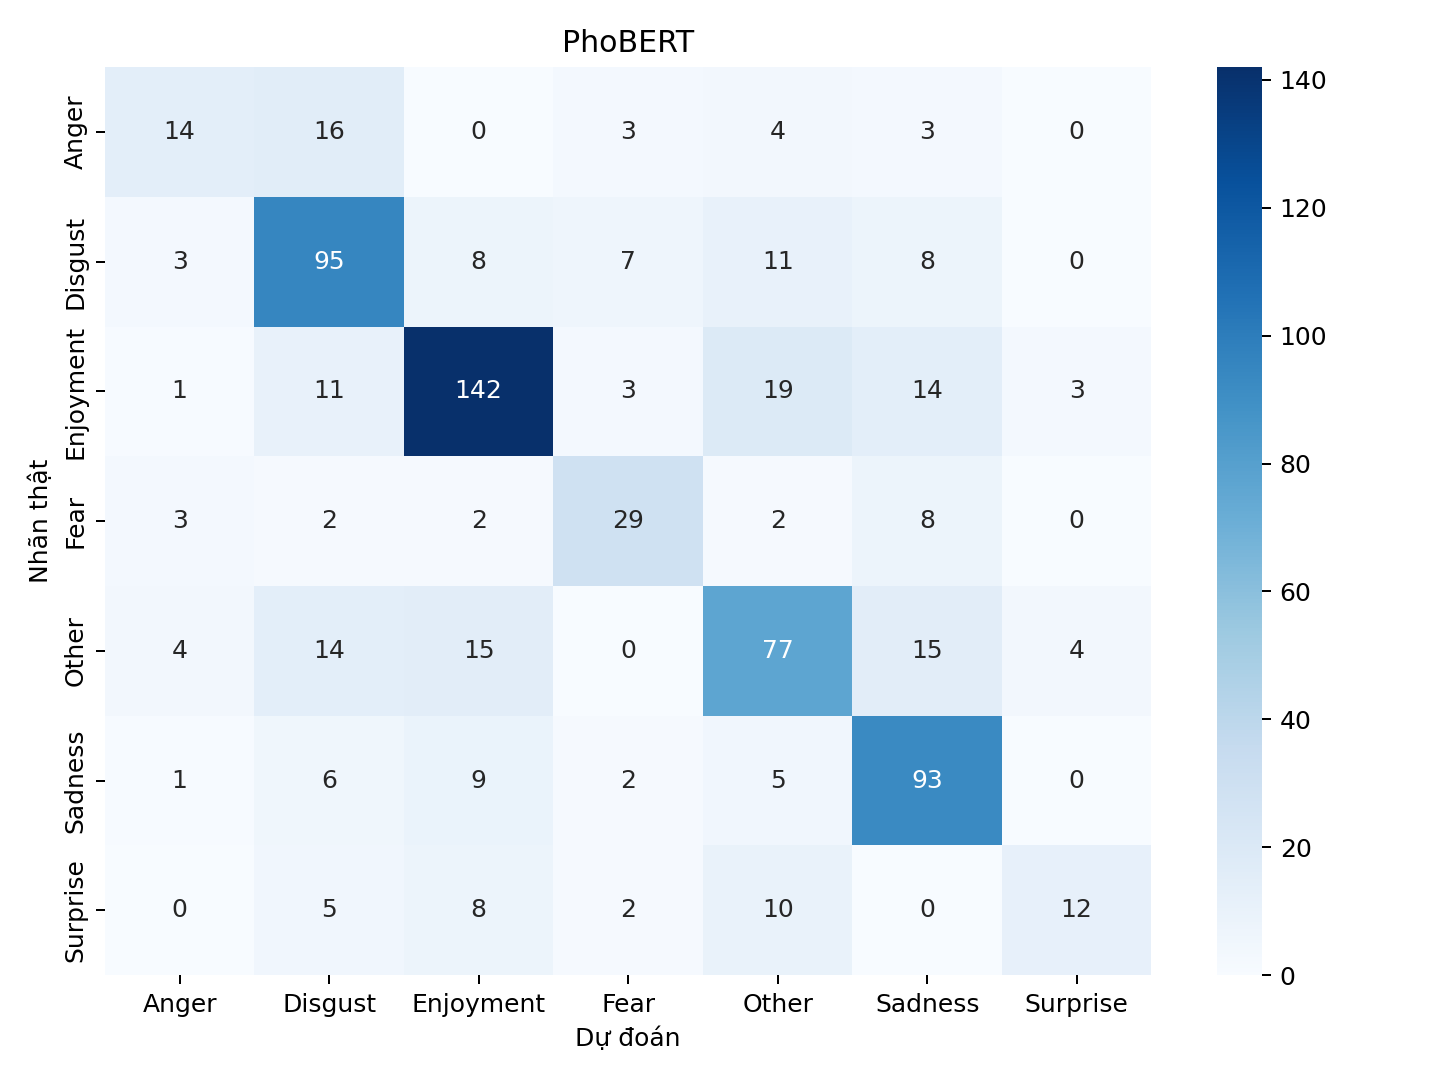

,TF-IDF + SVM,CNN + Word2Vec,PhoBERT,ViSoBERT
Anger,0.395062,0.325000,0.424242,0.465753
Disgust,0.531365,0.543478,0.676157,0.582090
Enjoyment,0.642298,0.702970,0.753316,0.706186
Fear,0.715789,0.619048,0.630435,0.694737
Other,0.511628,0.524345,0.599222,0.548263
Sadness,0.610169,0.687500,0.723735,0.702929
Surprise,0.516129,0.470588,0.428571,0.468750


In [18]:
best_key=comparison.iloc[0]['key'] #lấy hàng đầu tiên của bảng comparison: Phobert (hàng 1 
best_rows=pd.read_csv(PROJECT_ROOT/'results'/best_key/'predictions.csv')
errors=best_rows[best_rows.label!=best_rows.prediction].copy()
errors.to_csv(PROJECT_ROOT/'results/error_analysis.csv',index=False,encoding='utf-8-sig')
display(errors[['text','label','prediction']].head(20))
display(errors.groupby(['label','prediction']).size().sort_values(ascending=False).head(10).rename('số lỗi').to_frame())
display(Image(filename=str(PROJECT_ROOT/'results'/best_key/'confusion_matrix.png')))
per_label=pd.DataFrame({m['model']:{label:m['report'][label]['f1-score'] for label in LABELS} for m in metrics})
per_label.to_csv(PROJECT_ROOT/'results/per_label_f1.csv',encoding='utf-8-sig'); display(per_label)

## 12. Demo trực tiếp bằng checkpoint đã lưu
Chạy cell import/cấu hình ở mục 1, cell định nghĩa TextCNN ở mục 6 và cell dưới để demo sau khi restart kernel. Không cần chạy huấn luyện. Giao diện Streamlit dùng chính các cell được đánh dấu `demo_safe` trong notebook, bảo đảm cùng tiền xử lý và kiến trúc.

Điểm SVM là decision score, **không phải xác suất**. CNN/Transformer hiển thị softmax nhưng chưa hiệu chuẩn, không phải mức chắc chắn tuyệt đối.

In [31]:
def predict_saved(text,key):
    if not str(text).strip(): raise ValueError('Vui lòng nhập một câu không rỗng.')
    raw=normalized(text); dest=PROJECT_ROOT/'models'/key
    if key=='svm':
        b=joblib.load(dest/'model.joblib'); x=hstack([b['word'].transform([segmented(raw)]),b['char'].transform([raw])]).tocsr()
        scores=b['model'].decision_function(x)[0]; score_type='Decision score (không phải xác suất)'
    elif key=='cnn_word2vec':
        b=torch.load(dest/'model.pt',map_location='cpu',weights_only=False)
        model=TextCNN(b['embeddings'],b['params']); model.load_state_dict(b['state_dict']); model.eval()
        with torch.no_grad(): scores=model(cnn_ids([segmented(raw)],b['vocab'],b['params']['max_length'])).softmax(1)[0].numpy()
        score_type='Softmax (chưa hiệu chuẩn)'
    elif key in ['phobert','visobert']:
        tok=AutoTokenizer.from_pretrained(dest,use_fast=False,local_files_only=True)
        model=AutoModelForSequenceClassification.from_pretrained(dest,local_files_only=True); model.eval()
        value=segmented(raw) if key=='phobert' else raw
        x=tok(value,return_tensors='pt',truncation=True,max_length=CONFIG['transformer']['max_length'])
        with torch.no_grad(): scores=model(**x).logits.softmax(1)[0].numpy()
        score_type='Softmax (chưa hiệu chuẩn)'
    else: raise ValueError('Tên mô hình không hợp lệ')
    table=pd.DataFrame({'label':LABELS,'cảm xúc':[LABEL_VI[l] for l in LABELS],'score':scores.astype(float)}).sort_values('score',ascending=False)
    return table,score_type

In [25]:
DEMO_TEXT = 'Tôi rất vui vì cuối cùng cũng làm được rồi!'
DEMO_MODEL = ''
demo_result,score_type=predict_saved(DEMO_TEXT,DEMO_MODEL)
print(DEMO_TEXT); print(score_type); display(demo_result)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 4671.13it/s]


Tôi rất vui vì cuối cùng cũng làm được rồi!
Softmax (chưa hiệu chuẩn)


,label,cảm xúc,score
2,Enjoyment,Vui thích,0.879954
6,Surprise,Ngạc nhiên,0.039045
4,Other,Khác,0.026500
5,Sadness,Buồn,0.024734
3,Fear,Sợ hãi,0.013706
1,Disgust,Ghê tởm,0.008184
0,Anger,Tức giận,0.007877


## 13. Tài liệu tham khảo
- Ho và cộng sự. Emotion Recognition for Vietnamese Social Media Text. https://arxiv.org/abs/1911.09339
- Mikolov và cộng sự. Efficient Estimation of Word Representations in Vector Space. https://arxiv.org/abs/1301.3781
- Kim. Convolutional Neural Networks for Sentence Classification. https://aclanthology.org/D14-1181/
- Nguyen và Nguyen. PhoBERT. https://aclanthology.org/2020.findings-emnlp.92/
- Nguyen và cộng sự. ViSoBERT. https://aclanthology.org/2023.emnlp-main.315/
- Slide môn NLP: Bài 3 tiền xử lý, Bài 4 biểu diễn, Bài 5 sentiment, Bài 6.2 phân loại.

Nguồn được dùng để mô tả dữ liệu và phương pháp. Phần kết quả chỉ báo cáo lần chạy trong đồ án này.

In [32]:
# Check link to run terminal:
import sys
print(sys.executable)

d:\2. PERSONALIZATION\8. PYTHON-REINSTALL\python.exe
